# Predictive Parking Space Marketplace - ML Project
Complete ML Pipeline with Chi-Square Feature Selection, EDA, Models & Comparison

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import chi2, SelectKBest

from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Libraries imported successfully.")

Libraries imported successfully.


## Load Dataset

In [37]:
from pathlib import Path

USE_SAMPLE_DATA = True  # Set to False to load your downloaded CSV instead.
dataset_filename = "IIoT_Smart_Parking_Management.csv"

if USE_SAMPLE_DATA:
    parking_source_df = pd.DataFrame([
        {"parking_id": "CHN001", "name": "T Nagar - Pondy Bazaar", "city": "Chennai", "latitude": 13.0418, "longitude": 80.2337, "price_per_hour": 60, "available_spaces": 8, "total_spaces": 20, "Occupancy_Status": "Free"},
        {"parking_id": "CHN002", "name": "Chennai Central", "city": "Chennai", "latitude": 13.0827, "longitude": 80.2707, "price_per_hour": 50, "available_spaces": 3, "total_spaces": 18, "Occupancy_Status": "Free"},
        {"parking_id": "CHN003", "name": "Marina Beach - Lighthouse", "city": "Chennai", "latitude": 13.0500, "longitude": 80.2824, "price_per_hour": 80, "available_spaces": 0, "total_spaces": 25, "Occupancy_Status": "Occupied"},
        {"parking_id": "CHN004", "name": "Guindy Metro", "city": "Chennai", "latitude": 13.0067, "longitude": 80.2206, "price_per_hour": 40, "available_spaces": 7, "total_spaces": 16, "Occupancy_Status": "Free"},
        {"parking_id": "CHN005", "name": "Adyar - Gandhi Nagar", "city": "Chennai", "latitude": 13.0064, "longitude": 80.2572, "price_per_hour": 45, "available_spaces": 4, "total_spaces": 14, "Occupancy_Status": "Free"},
        {"parking_id": "CHN006", "name": "Velachery MRTS", "city": "Chennai", "latitude": 12.9815, "longitude": 80.2180, "price_per_hour": 35, "available_spaces": 11, "total_spaces": 22, "Occupancy_Status": "Free"},
        {"parking_id": "CHN007", "name": "Thoraipakkam - OMR", "city": "Chennai", "latitude": 12.9416, "longitude": 80.2362, "price_per_hour": 30, "available_spaces": 0, "total_spaces": 20, "Occupancy_Status": "Occupied"},
        {"parking_id": "CHN008", "name": "Anna Nagar Tower Park", "city": "Chennai", "latitude": 13.0850, "longitude": 80.2101, "price_per_hour": 40, "available_spaces": 5, "total_spaces": 18, "Occupancy_Status": "Free"},
        {"parking_id": "CHN009", "name": "Egmore Railway Station", "city": "Chennai", "latitude": 13.0732, "longitude": 80.2609, "price_per_hour": 50, "available_spaces": 0, "total_spaces": 15, "Occupancy_Status": "Occupied"},
        {"parking_id": "CHN010", "name": "Mylapore - Kapaleeshwarar Temple", "city": "Chennai", "latitude": 13.0335, "longitude": 80.2697, "price_per_hour": 55, "available_spaces": 2, "total_spaces": 12, "Occupancy_Status": "Free"},
        {"parking_id": "CHN011", "name": "Nungambakkam", "city": "Chennai", "latitude": 13.0569, "longitude": 80.2425, "price_per_hour": 50, "available_spaces": 6, "total_spaces": 16, "Occupancy_Status": "Free"},
        {"parking_id": "CHN012", "name": "Sholinganallur - OMR", "city": "Chennai", "latitude": 12.9010, "longitude": 80.2279, "price_per_hour": 25, "available_spaces": 0, "total_spaces": 20, "Occupancy_Status": "Occupied"},
        {"parking_id": "CHN013", "name": "Chromepet", "city": "Chennai", "latitude": 12.9516, "longitude": 80.1462, "price_per_hour": 30, "available_spaces": 8, "total_spaces": 18, "Occupancy_Status": "Free"},
        {"parking_id": "CHN014", "name": "Tambaram", "city": "Chennai", "latitude": 12.9249, "longitude": 80.1000, "price_per_hour": 25, "available_spaces": 4, "total_spaces": 15, "Occupancy_Status": "Free"},
        {"parking_id": "CHN015", "name": "Perungudi - OMR", "city": "Chennai", "latitude": 12.9609, "longitude": 80.2462, "price_per_hour": 35, "available_spaces": 0, "total_spaces": 22, "Occupancy_Status": "Occupied"},
        {"parking_id": "CHN016", "name": "Koyambedu", "city": "Chennai", "latitude": 13.0732, "longitude": 80.1940, "price_per_hour": 40, "available_spaces": 3, "total_spaces": 20, "Occupancy_Status": "Free"},
    ])
    parking_source_df["Timestamp"] = pd.date_range(
        start="2026-10-22 09:00:00", periods=len(parking_source_df), freq="h"
    )
    url = "synthetic_chennai_sample_data"
else:
    candidate_paths = [
        Path("/kaggle/input/smart-parking-management-dataset") / dataset_filename,
        Path.cwd() / dataset_filename,
        Path.home() / "Downloads" / dataset_filename,
        Path.home() / dataset_filename,
    ]
    dataset_path = next((path for path in candidate_paths if path.is_file()), None)

    if dataset_path is None:
        try:
            import tkinter as tk
            from tkinter import filedialog

            root = tk.Tk()
            root.withdraw()
            root.attributes("-topmost", True)
            selected_path = filedialog.askopenfilename(
                title="Select IIoT_Smart_Parking_Management.csv",
                filetypes=[("CSV files", "*.csv")],
            )
            root.destroy()
            if selected_path:
                dataset_path = Path(selected_path)
        except Exception:
            dataset_path = None

    if dataset_path is None or not dataset_path.is_file():
        raise FileNotFoundError(
            f"Could not find {dataset_filename}. Select the downloaded CSV "
            "or set dataset_path to its full local path."
        )

    url = str(dataset_path)
    parking_source_df = pd.read_csv(dataset_path)

df = parking_source_df.copy()
print(f"Loaded {len(df)} parking records from {url}.")
df.head()

Loaded 16 parking records from synthetic_chennai_sample_data.


,parking_id,name,city,latitude,longitude,price_per_hour,available_spaces,total_spaces,Occupancy_Status,Timestamp
0,CHN001,T Nagar - Pondy Bazaar,Chennai,13.0418,80.2337,60,8,20,Free,2026-10-22 09:00:00
1,CHN002,Chennai Central,Chennai,13.0827,80.2707,50,3,18,Free,2026-10-22 10:00:00
2,CHN003,Marina Beach - Lighthouse,Chennai,13.0500,80.2824,80,0,25,Occupied,2026-10-22 11:00:00
3,CHN004,Guindy Metro,Chennai,13.0067,80.2206,40,7,16,Free,2026-10-22 12:00:00
4,CHN005,Adyar - Gandhi Nagar,Chennai,13.0064,80.2572,45,4,14,Free,2026-10-22 13:00:00


## Dataset Info

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   parking_id        16 non-null     object        
 1   name              16 non-null     object        
 2   city              16 non-null     object        
 3   latitude          16 non-null     float64       
 4   longitude         16 non-null     float64       
 5   price_per_hour    16 non-null     int64         
 6   available_spaces  16 non-null     int64         
 7   total_spaces      16 non-null     int64         
 8   Occupancy_Status  16 non-null     object        
 9   Timestamp         16 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 1.4+ KB


In [38]:
target = "Occupancy_Status"
if target not in df.columns:
    raise KeyError(f"Dataset must contain the target column {target!r}.")

status_map = {
    "occupied": 1, "unavailable": 1, "yes": 1, "true": 1, "1": 1,
    "free": 0, "available": 0, "no": 0, "false": 0, "0": 0,
}
status = df[target].astype(str).str.strip().str.lower()
encoded_status = status.map(status_map)
if encoded_status.isna().any():
    unknown_values = sorted(status[encoded_status.isna()].unique().tolist())
    raise ValueError(f"Unrecognized {target} values: {unknown_values}")
df[target] = encoded_status.astype(int)

if "Timestamp" in df.columns:
    timestamp = pd.to_datetime(df["Timestamp"], errors="coerce")
    df["timestamp_hour"] = timestamp.dt.hour
    df["timestamp_day_of_week"] = timestamp.dt.dayofweek
    df = df.drop(columns=["Timestamp"])

# Do not feed IDs, names, or a direct availability count into occupancy prediction.
excluded_features = [target]
excluded_features.extend(
    column for column in ("parking_id", "name", "available_spaces")
    if column in df.columns
 )
X = df.drop(columns=excluded_features)
y = df[target]
categorical_columns = X.select_dtypes(include=["object", "category"]).columns.tolist()
X = pd.get_dummies(X, columns=categorical_columns, dtype=int)
X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)
X = X.loc[:, X.nunique(dropna=False) > 1]

print("Prepared features:", X.shape)
print("Target counts:", y.value_counts().sort_index().to_dict())
df.head()

Prepared features: (16, 6)
Target counts: {0: 11, 1: 5}


,parking_id,name,city,latitude,longitude,price_per_hour,available_spaces,total_spaces,Occupancy_Status,timestamp_hour,timestamp_day_of_week
0,CHN001,T Nagar - Pondy Bazaar,Chennai,13.0418,80.2337,60,8,20,0,9,3
1,CHN002,Chennai Central,Chennai,13.0827,80.2707,50,3,18,0,10,3
2,CHN003,Marina Beach - Lighthouse,Chennai,13.0500,80.2824,80,0,25,1,11,3
3,CHN004,Guindy Metro,Chennai,13.0067,80.2206,40,7,16,0,12,3
4,CHN005,Adyar - Gandhi Nagar,Chennai,13.0064,80.2572,45,4,14,0,13,3


## EDA - Countplot of Target

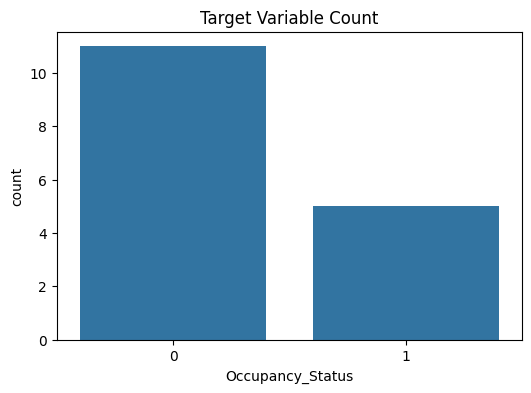

In [39]:
plt.figure(figsize=(6,4))
sns.countplot(x=df['Occupancy_Status'])
plt.title("Target Variable Count")
plt.show()

## Correlation Heatmap

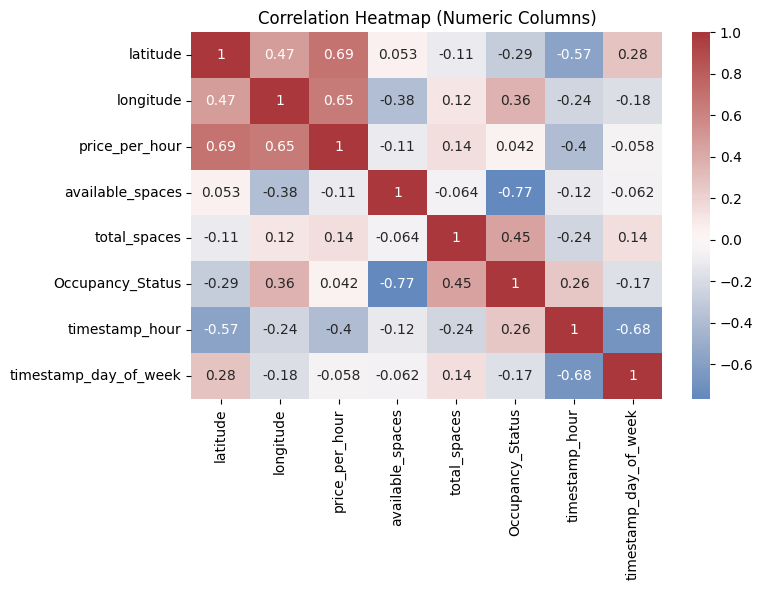

In [40]:
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="vlag", center=0)
plt.title("Correlation Heatmap (Numeric Columns)")
plt.tight_layout()
plt.show()

## Prepared Model Features

In [41]:
X.head()

,latitude,longitude,price_per_hour,total_spaces,timestamp_hour,timestamp_day_of_week
0,13.0418,80.2337,60,20,9,3
1,13.0827,80.2707,50,18,10,3
2,13.0500,80.2824,80,25,11,3
3,13.0067,80.2206,40,16,12,3
4,13.0064,80.2572,45,14,13,3


In [43]:
if y.nunique() < 2:
    raise ValueError("Occupancy_Status must contain both free and occupied examples.")

stratify_target = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_target
 )

scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
 )
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
 )

print(f"Train/test split: {len(X_train)} / {len(X_test)} rows.")
print("Scaler fitted on training data only.")

Train/test split: 12 / 4 rows.
Scaler fitted on training data only.


## Chi-Square Feature Selection

In [44]:
selector = SelectKBest(score_func=chi2, k=min(10, X_train_scaled.shape[1]))
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

chi_scores = pd.DataFrame({
    "Feature": X_train_scaled.columns[selector.get_support()],
    "Chi2 Score": selector.scores_[selector.get_support()],
}).sort_values(by="Chi2 Score", ascending=False)

chi_scores

,Feature,Chi2 Score
5,timestamp_day_of_week,0.500000
1,longitude,0.347692
3,total_spaces,0.179787
2,price_per_hour,0.110865
0,latitude,0.097255
4,timestamp_hour,0.065868


## Train Models

In [45]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

accuracies = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_selected, y_train)
    predictions[name] = model.predict(X_test_selected)
    accuracies[name] = accuracy_score(y_test, predictions[name])

accuracies

{'Logistic Regression': 0.75, 'Decision Tree': 0.25, 'Random Forest': 0.5}

## Accuracy Comparison Graph

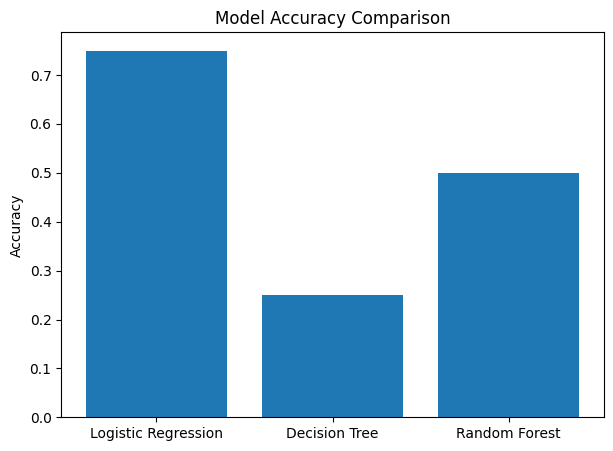

In [46]:
plt.figure(figsize=(7,5))
plt.bar(accuracies.keys(), accuracies.values())
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.show()

In [47]:
from sklearn.metrics import precision_recall_fscore_support

summary_rows = []
for model_name, model_predictions in predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, model_predictions, average="binary", zero_division=0
    )
    summary_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, model_predictions),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
    })

performance_summary = pd.DataFrame(summary_rows)
print("\n=== Model Performance Summary ===")
print(performance_summary.round(4))

most_efficient_model = performance_summary.loc[performance_summary["Accuracy"].idxmax()]
print(
    f"\nHighest-accuracy model: {most_efficient_model['Model']} "
    f"({most_efficient_model['Accuracy']:.4f})"
 )


=== Model Performance Summary ===
                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression      0.75     0.0000     0.0       0.0
1        Decision Tree      0.25     0.2500     1.0       0.4
2        Random Forest      0.50     0.3333     1.0       0.5

Highest-accuracy model: Logistic Regression (0.7500)


In [48]:
import json
import os
import urllib.request

import numpy as np
import pandas as pd

PARKING_COLUMN_MAP = {
    "parking_id": "parking_id",
    "name": "name",
    "latitude": "latitude",
    "longitude": "longitude",
    "price_per_hour": "price_per_hour",
    "available_spaces": "available_spaces",
}

# Increase a weight to make that factor matter more in the final ranking.
RANKING_WEIGHTS = {"price": 0.40, "availability": 0.20, "distance": 0.40}

def prepare_parking_spaces(source_df, column_map=PARKING_COLUMN_MAP):
    """Return one row per parking alternative in the recommender's schema."""
    required = ["parking_id", "name", "latitude", "longitude", "price_per_hour"]
    missing = [key for key in required if not column_map.get(key) or column_map[key] not in source_df.columns]
    has_availability = (
        column_map.get("available_spaces") in source_df.columns
        or column_map.get("occupancy_status") in source_df.columns
    )
    if missing or not has_availability:
        raise ValueError(
            "Map parking_id, name, latitude, longitude, price_per_hour, and "
            "available_spaces (or occupancy_status) to real columns. "
            f"Missing mappings: {missing}; source columns: {source_df.columns.tolist()}"
        )

    result = pd.DataFrame({
        "parking_id": source_df[column_map["parking_id"]],
        "name": source_df[column_map["name"]],
        "latitude": pd.to_numeric(source_df[column_map["latitude"]], errors="coerce"),
        "longitude": pd.to_numeric(source_df[column_map["longitude"]], errors="coerce"),
        "price_per_hour": pd.to_numeric(source_df[column_map["price_per_hour"]], errors="coerce"),
    })
    if column_map.get("available_spaces") in source_df.columns:
        result["available_spaces"] = pd.to_numeric(
            source_df[column_map["available_spaces"]], errors="coerce"
        )
    else:
        status = source_df[column_map["occupancy_status"]].astype(str).str.strip().str.lower()
        free_statuses = {"free", "available", "no", "false", "0"}
        occupied_statuses = {"occupied", "unavailable", "yes", "true", "1"}
        unknown = ~status.isin(free_statuses | occupied_statuses)
        if unknown.any():
            raise ValueError(f"Unrecognized occupancy values: {status[unknown].unique().tolist()}")
        result["available_spaces"] = status.isin(free_statuses).astype(int)

    result = result.dropna(subset=["latitude", "longitude", "price_per_hour", "available_spaces"])
    result = result[result["available_spaces"] > 0].copy()
    if result.empty:
        raise ValueError("No valid parking alternatives with available spaces remain.")
    return result

def _normalized_score(values, higher_is_better=True):
    values = pd.to_numeric(values, errors="coerce")
    low, high = values.min(), values.max()
    if pd.isna(low) or pd.isna(high) or low == high:
        return pd.Series(1.0, index=values.index)
    score = (values - low) / (high - low)
    return score if higher_is_better else 1 - score

def rank_parking_spaces(
    parking_spaces, destination, api_key=None, weights=None, mode="driving",
    departure_time=None, max_price_per_hour=None, max_distance_km=None,
    distance_client=None,
 ):
    """Rank available spaces by configurable price, availability, and route distance."""
    required = {"parking_id", "name", "latitude", "longitude", "price_per_hour", "available_spaces"}
    missing = required.difference(parking_spaces.columns)
    if missing:
        raise ValueError(f"parking_spaces is missing required columns: {sorted(missing)}")

    candidates = parking_spaces.loc[parking_spaces["available_spaces"] > 0].copy().reset_index(drop=True)
    if max_price_per_hour is not None:
        if not np.isfinite(max_price_per_hour) or max_price_per_hour <= 0:
            raise ValueError("max_price_per_hour must be a positive number.")
        candidates = candidates[candidates["price_per_hour"] <= max_price_per_hour].copy()
    if candidates.empty:
        raise ValueError("No available parking alternatives satisfy the price limit.")

    if distance_client is None:
        try:
            import googlemaps
        except ImportError as exc:
            raise ImportError("Install the googlemaps package to request route distances.") from exc
        api_key = api_key or os.getenv("GOOGLE_MAPS_API_KEY")
        if not api_key:
            raise ValueError("Set GOOGLE_MAPS_API_KEY or pass api_key explicitly.")
        distance_client = googlemaps.Client(key=api_key)

    distances, durations = [], []
    coordinates = list(zip(candidates["latitude"], candidates["longitude"]))
    for start in range(0, len(coordinates), 25):
        batch = coordinates[start:start + 25]
        response = distance_client.distance_matrix(
            origins=batch, destinations=[destination], mode=mode, units="metric",
            departure_time=departure_time,
        )
        for row in response.get("rows", []):
            elements = row.get("elements", [])
            element = elements[0] if elements else {}
            if element.get("status") != "OK":
                distances.append(np.nan)
                durations.append(np.nan)
            else:
                distances.append(element["distance"]["value"] / 1000)
                durations.append(element["duration"]["value"] / 60)

    if len(distances) != len(candidates):
        raise ValueError("Google Maps returned an incomplete distance matrix.")
    candidates["distance_km"] = distances
    candidates["travel_minutes"] = durations
    candidates = candidates.dropna(subset=["distance_km", "travel_minutes"]).copy()
    if max_distance_km is not None:
        if not np.isfinite(max_distance_km) or max_distance_km <= 0:
            raise ValueError("max_distance_km must be a positive number.")
        candidates = candidates[candidates["distance_km"] <= max_distance_km].copy()
    if candidates.empty:
        raise ValueError("No available parking alternatives satisfy the distance limit.")

    weights = RANKING_WEIGHTS.copy() if weights is None else weights
    if set(weights) != {"price", "availability", "distance"}:
        raise ValueError("weights must contain price, availability, and distance.")
    try:
        weights = {key: float(value) for key, value in weights.items()}
    except (TypeError, ValueError) as exc:
        raise ValueError("Ranking weights must be numeric.") from exc
    if any(not np.isfinite(value) or value < 0 for value in weights.values()):
        raise ValueError("Ranking weights must be finite and non-negative.")
    weight_total = sum(weights.values())
    if weight_total <= 0:
        raise ValueError("At least one ranking weight must be greater than zero.")
    weights = {key: value / weight_total for key, value in weights.items()}

    candidates["price_score"] = _normalized_score(candidates["price_per_hour"], higher_is_better=False)
    candidates["availability_score"] = _normalized_score(candidates["available_spaces"])
    candidates["distance_score"] = _normalized_score(candidates["distance_km"], higher_is_better=False)
    candidates["recommendation_score"] = (
        weights["price"] * candidates["price_score"]
        + weights["availability"] * candidates["availability_score"]
        + weights["distance"] * candidates["distance_score"]
    )
    return candidates.sort_values(
        ["recommendation_score", "distance_km", "price_per_hour"],
        ascending=[False, True, True],
    ).reset_index(drop=True)

def explain_with_ollama(ranked_spaces, model="llama3.2", top_n=5):
    """Ask local Ollama to explain the deterministic ranking; it cannot change it."""
    top = ranked_spaces.head(top_n)[[
        "name", "price_per_hour", "available_spaces", "distance_km",
        "travel_minutes", "recommendation_score",
    ]].to_dict(orient="records")
    prompt = (
        "Explain these already-ranked parking choices briefly using only the supplied data. "
        "Do not change their order or invent facts. Data: " + json.dumps(top)
    )
    request = urllib.request.Request(
        "http://localhost:11434/api/generate",
        data=json.dumps({"model": model, "prompt": prompt, "stream": False}).encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="POST",
    )
    with urllib.request.urlopen(request, timeout=120) as response:
        return json.loads(response.read().decode("utf-8"))["response"]

print("Parking ranking functions are ready. Adjust RANKING_WEIGHTS to tune price, availability, and distance.")

Parking ranking functions are ready. Adjust RANKING_WEIGHTS to tune price, availability, and distance.


In [50]:
from math import asin, cos, radians, sin, sqrt

class DemoDistanceClient:
    """Return synthetic straight-line distances for a no-API notebook demo."""
    def distance_matrix(self, origins, destinations, **kwargs):
        destination_lat, destination_lon = map(float, destinations[0])
        rows = []
        for origin_lat, origin_lon in origins:
            lat1, lon1, lat2, lon2 = map(
                radians, [float(origin_lat), float(origin_lon), destination_lat, destination_lon]
            )
            delta_lat, delta_lon = lat2 - lat1, lon2 - lon1
            haversine = (
                sin(delta_lat / 2) ** 2
                + cos(lat1) * cos(lat2) * sin(delta_lon / 2) ** 2
            )
            distance_km = 6371 * 2 * asin(sqrt(haversine))
            travel_minutes = distance_km / 25 * 60
            rows.append({
                "elements": [{
                    "status": "OK",
                    "distance": {"value": round(distance_km * 1000)},
                    "duration": {"value": round(travel_minutes * 60)},
                }]
            })
        return {"rows": rows}

demo_parking_spaces = prepare_parking_spaces(
    parking_source_df, PARKING_COLUMN_MAP
 )
demo_ranked_parking = rank_parking_spaces(
    demo_parking_spaces,
    destination=(13.0827, 80.2707),  # Chennai Central
    weights=RANKING_WEIGHTS,
    max_price_per_hour=60,
    max_distance_km=10,
    distance_client=DemoDistanceClient(),
 )
assert (demo_ranked_parking["price_per_hour"] <= 60).all()
assert (demo_ranked_parking["distance_km"] <= 10).all()
demo_ranked_parking["distance_type"] = "Synthetic straight-line demo"
display(demo_ranked_parking[[
    "name", "price_per_hour", "available_spaces", "distance_km",
    "travel_minutes", "recommendation_score", "distance_type",
 ]].head(10))

,name,price_per_hour,available_spaces,distance_km,travel_minutes,recommendation_score,distance_type
0,Chennai Central,50,3,0.000,0.000000,0.633333,Synthetic straight-line demo
1,Anna Nagar Tower Park,40,5,6.568,15.766667,0.594831,Synthetic straight-line demo
2,Nungambakkam,50,6,4.190,10.050000,0.538653,Synthetic straight-line demo
3,Koyambedu,40,3,8.374,20.100000,0.444252,Synthetic straight-line demo
4,Adyar - Gandhi Nagar,45,4,8.609,20.666667,0.366667,Synthetic straight-line demo
5,T Nagar - Pondy Bazaar,60,8,6.062,14.550000,0.318341,Synthetic straight-line demo
6,Mylapore - Kapaleeshwarar Temple,55,2,5.472,13.133333,0.245754,Synthetic straight-line demo


## Parking Recommendation Setup

Adjust `RANKING_WEIGHTS` in the code cell above to tune the factors. The default gives price 40%, availability 20%, and distance 40%. `max_price_per_hour` is a hard INR/hour budget cap; `max_distance_km` is a hard route-distance cap. Set either limit to `None` to disable it.

The offline Chennai example above uses synthetic straight-line distances from Chennai Central so it runs without credentials. It is only a scoring demonstration, not a driving route or live parking feed. For real routes, enable the Google Maps Distance Matrix API and set `GOOGLE_MAPS_API_KEY` in your environment. Ollama is optional and only explains the completed ranking.

Map `PARKING_COLUMN_MAP` to the source columns, then call the live ranker like this:

```python
parking_spaces = prepare_parking_spaces(parking_source_df, PARKING_COLUMN_MAP)
ranked_parking = rank_parking_spaces(
    parking_spaces,
    destination="Your destination address or (latitude, longitude)",
    weights=RANKING_WEIGHTS,
    max_price_per_hour=60,  # INR per hour; use None for no cap
    max_distance_km=10,      # Google Maps route distance; use None for no cap
    departure_time=None,
 )
display(ranked_parking.head(10))

# Optional local explanation; does not modify ranked_parking
print(explain_with_ollama(ranked_parking, model="llama3.2"))
```